# 🦟 VectorIA — Análisis Exploratorio de Datos (EDA)
## Dataset 5: MLMI-2024 — Imágenes microscópicas de larvas (bonus)

**Módulo:** CNN — Identificación de larvas (funcionalidad opcional)  
**Dataset:** MLMI-2024 (Mosquito Larvae Microscopic Images)  
**Fuente:** [Mendeley Data](https://data.mendeley.com/datasets/pgby6jmtp4/1)  
**Notebook:** `05_EDA_MLMI_2024.ipynb`

### Objetivo
Explorar las imágenes de larvas de *Aedes aegypti* y *Culex quinquefasciatus*, considerando sus cuatro regiones anatómicas (*abdomen, full body, head, siphon*), para describir la distribución de los datos, la calidad visual y las posibles inconsistencias **antes del entrenamiento**.


## 1. Importación de librerías

Se importan una sola vez las librerías para recorrer las carpetas, organizar los resultados, procesar imágenes y visualizar los datos.

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image, ImageOps
from IPython.display import display

EXTENSIONES_IMAGEN = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".tif", ".tiff"}
ESPECIES = ["Aedes aegypti", "Culex quinquefasciatus"]
REGIONES = ["abdomen", "full body", "head", "siphon"]

## 2. Ubicación del dataset

Se utiliza la ruta exacta del dataset descomprimido. Las carpetas de las especies están dentro de esta ubicación.

In [2]:
ruta = Path(r"C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\data\raw\mosquitos\Bonus-MLMI-2024")

print("Dataset:", ruta)
for especie in ESPECIES:
    print("\n", especie)
    for region in REGIONES:
        print("  -", region)

Dataset: C:\Users\andre\Documents\CUC\Cuatrimeste_lll_2026\InteligenciaArticial\Proyecto\P2\VectorIA\data\raw\mosquitos\Bonus-MLMI-2024

 Aedes aegypti
  - abdomen
  - full body
  - head
  - siphon

 Culex quinquefasciatus
  - abdomen
  - full body
  - head
  - siphon


## 3. Exploración de la estructura de carpetas

Se revisa la organización real de los directorios de especies y regiones anatómicas.

In [3]:
for especie in ESPECIES:
    carpeta_especie = ruta / especie
    print(f"\n{especie}:")
    for elemento in sorted(carpeta_especie.iterdir()):
        if elemento.is_dir():
            print("  [Carpeta]", elemento.name)
        else:
            print("  [Archivo]", elemento.name)


Aedes aegypti:
  [Carpeta] abdomen
  [Carpeta] full body
  [Carpeta] head
  [Carpeta] siphon

Culex quinquefasciatus:
  [Carpeta] abdomen
  [Carpeta] full body
  [Carpeta] head
  [Carpeta] siphon


## 4. Construcción del inventario y validación de imágenes

Se recorren todas las imágenes y se registran sus metadatos, estadísticas visuales e identificadores para detectar duplicados. Para comparar brillo, contraste y nitidez, cada fotografía se analiza sobre una **copia reducida a un máximo de 256 píxeles por lado**, sin modificar el archivo original. La nitidez basada en Laplaciano es una medida orientativa, no una garantía de calidad.

In [4]:
def sha256_archivo(archivo):
    digesto = hashlib.sha256()
    with archivo.open("rb") as f:
        for bloque in iter(lambda: f.read(1024 * 1024), b""):
            digesto.update(bloque)
    return digesto.hexdigest()


def hash_visual(imagen):
    """dHash: huella aproximada útil para encontrar candidatos a similitud."""
    gris = ImageOps.grayscale(imagen).resize((9, 8), Image.Resampling.LANCZOS)
    valores = np.asarray(gris, dtype=np.int16)
    bits = (valores[:, 1:] > valores[:, :-1]).ravel().astype(np.uint8)
    return np.packbits(bits).tobytes().hex()


registros = []
errores = []

for especie in ESPECIES:
    for region in REGIONES:
        carpeta = ruta / especie / region
        for archivo in sorted(carpeta.rglob("*")):
            if not archivo.is_file() or archivo.suffix.lower() not in EXTENSIONES_IMAGEN:
                continue
            try:
                # Verificación de integridad y lectura efectiva del archivo.
                with Image.open(archivo) as imagen:
                    imagen.verify()
                with Image.open(archivo) as imagen:
                    imagen.load()
                    ancho, alto = imagen.size
                    modo = imagen.mode
                    formato = imagen.format
                    dhash = hash_visual(imagen)
                    copia = imagen.convert("L")
                    copia.thumbnail((256, 256), Image.Resampling.LANCZOS)
                    matriz = np.asarray(copia, dtype=np.uint8)

                registros.append({
                    "Especie": especie,
                    "Región": region,
                    "Archivo": archivo.name,
                    "Ruta": str(archivo),
                    "Ancho": ancho,
                    "Alto": alto,
                    "Resolución": f"{ancho}x{alto}",
                    "Relación de aspecto": ancho / alto,
                    "Extensión": archivo.suffix.lower(),
                    "Formato real": formato,
                    "Modo de color": modo,
                    "Tamaño (KB)": archivo.stat().st_size / 1024,
                    "Brillo": float(matriz.mean()),
                    "Contraste": float(matriz.std()),
                    "Nitidez": float(cv2.Laplacian(matriz, cv2.CV_64F).var()),
                    "SHA256": sha256_archivo(archivo),
                    "dHash": dhash,
                })
            except Exception as exc:
                errores.append({"Especie": especie, "Región": region,
                                "Archivo": str(archivo), "Error": str(exc)})

df = pd.DataFrame(registros)
df_errores = pd.DataFrame(errores, columns=["Especie", "Región", "Archivo", "Error"])

print("Imágenes válidas:", len(df))
print("Archivos dañados o ilegibles:", len(df_errores))
display(df[["Especie", "Región", "Archivo", "Ancho", "Alto", "Modo de color"]].head(10))

Imágenes válidas: 800
Archivos dañados o ilegibles: 0


,Especie,Región,Archivo,Ancho,Alto,Modo de color
0,Aedes aegypti,abdomen,20231211_131111.jpg,3456,3456,RGB
1,Aedes aegypti,abdomen,20231211_131132.jpg,3456,3456,RGB
2,Aedes aegypti,abdomen,20231211_131207.jpg,3456,3456,RGB
3,Aedes aegypti,abdomen,20231211_131248.jpg,3456,3456,RGB
4,Aedes aegypti,abdomen,20231211_131334.jpg,3456,3456,RGB
5,Aedes aegypti,abdomen,20231211_131401.jpg,3456,3456,RGB
6,Aedes aegypti,abdomen,20231211_131554.jpg,3456,3456,RGB
7,Aedes aegypti,abdomen,20231211_131644.jpg,3456,3456,RGB
8,Aedes aegypti,abdomen,20231211_131720.jpg,3456,3456,RGB
9,Aedes aegypti,abdomen,20231211_131744.jpg,3456,3456,RGB


## 5. Cantidad total de imágenes

Se contabilizan las imágenes válidas y la cantidad de archivos detectados durante el recorrido.

In [5]:
print("Imágenes válidas:", len(df))
print("Imágenes dañadas:", len(df_errores))
print("Total de archivos de imagen revisados:", len(df) + len(df_errores))

Imágenes válidas: 800
Imágenes dañadas: 0
Total de archivos de imagen revisados: 800


## 6. Distribución por especie

Se determina cuántas imágenes corresponden a cada especie de mosquito.

In [6]:
conteo_especies = df["Especie"].value_counts().reindex(ESPECIES, fill_value=0)
display(conteo_especies.rename_axis("Especie").reset_index(name="Cantidad"))

,Especie,Cantidad
0,Aedes aegypti,400
1,Culex quinquefasciatus,400


## 7. Porcentaje por especie

Se representa la proporción de fotografías de cada especie dentro del dataset.

,Cantidad,Porcentaje (%)
Especie,,
Aedes aegypti,400,50.0
Culex quinquefasciatus,400,50.0


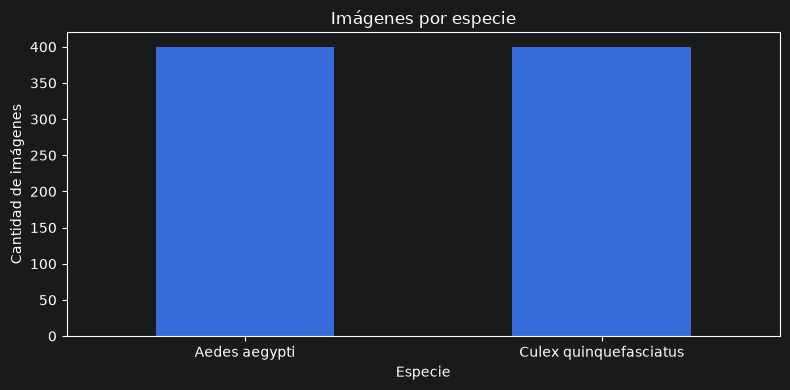

In [7]:
porcentajes_especies = (conteo_especies / len(df) * 100).round(2)
tabla_especies = pd.DataFrame({"Cantidad": conteo_especies, "Porcentaje (%)": porcentajes_especies})
display(tabla_especies)

ax = conteo_especies.plot(kind="bar", figsize=(8, 4), title="Imágenes por especie")
ax.set_xlabel("Especie")
ax.set_ylabel("Cantidad de imágenes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 8. Distribución por región anatómica

Se compara la representación de abdomen, cuerpo completo, cabeza y sifón, independientemente de la especie.

,Región,Cantidad
0,abdomen,200
1,full body,200
2,head,200
3,siphon,200


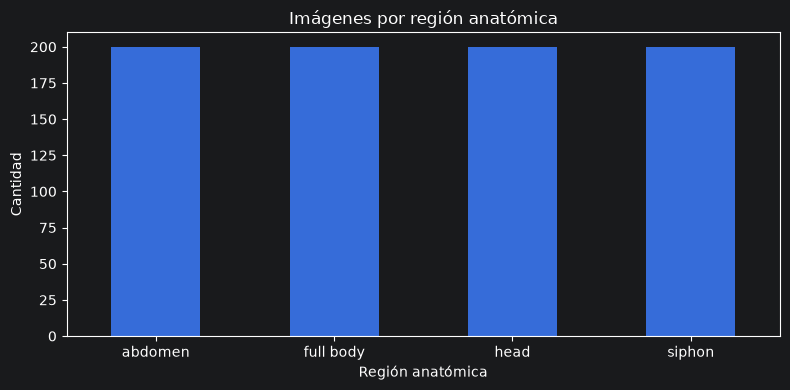

In [8]:
conteo_regiones = df["Región"].value_counts().reindex(REGIONES, fill_value=0)
display(conteo_regiones.rename_axis("Región").reset_index(name="Cantidad"))

ax = conteo_regiones.plot(kind="bar", figsize=(8, 4), title="Imágenes por región anatómica")
ax.set_xlabel("Región anatómica")
ax.set_ylabel("Cantidad")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 9. Distribución combinada: especie y región

Se analiza cuántas imágenes hay para cada combinación de especie y parte anatómica. Es importante que el modelo no confunda las diferencias de región con las diferencias entre especies.

Región,abdomen,full body,head,siphon
Especie,,,,
Aedes aegypti,100,100,100,100
Culex quinquefasciatus,100,100,100,100


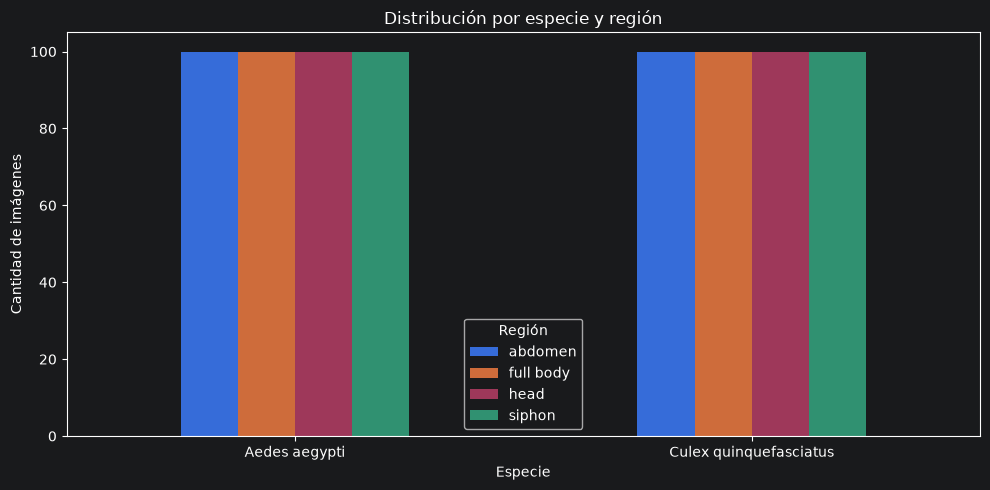

In [9]:
tabla_especie_region = pd.crosstab(df["Especie"], df["Región"])
tabla_especie_region = tabla_especie_region.reindex(index=ESPECIES, columns=REGIONES, fill_value=0)
display(tabla_especie_region)

ax = tabla_especie_region.plot(kind="bar", figsize=(10, 5))
ax.set_title("Distribución por especie y región")
ax.set_xlabel("Especie")
ax.set_ylabel("Cantidad de imágenes")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 10. Proporciones dentro de cada especie

Se calcula el porcentaje que representa cada región anatómica dentro de su especie para revelar desequilibrios que los conteos totales podrían ocultar.

Región,abdomen,full body,head,siphon
Especie,,,,
Aedes aegypti,25.0,25.0,25.0,25.0
Culex quinquefasciatus,25.0,25.0,25.0,25.0


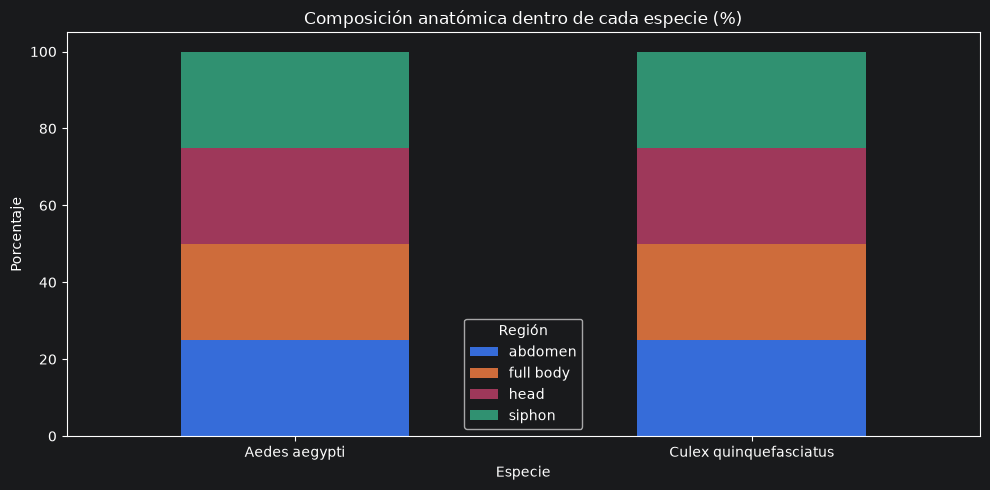

In [10]:
porcentaje_por_especie = tabla_especie_region.div(
    tabla_especie_region.sum(axis=1).replace(0, np.nan), axis=0
).mul(100).round(2)
display(porcentaje_por_especie)

ax = porcentaje_por_especie.plot(kind="bar", stacked=True, figsize=(10, 5))
ax.set_title("Composición anatómica dentro de cada especie (%)")
ax.set_xlabel("Especie")
ax.set_ylabel("Porcentaje")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Visualización de imágenes de ejemplo

Se muestra una fotografía de cada combinación de especie y región. La muestra permite revisar visualmente características morfológicas y diferencias de captura.

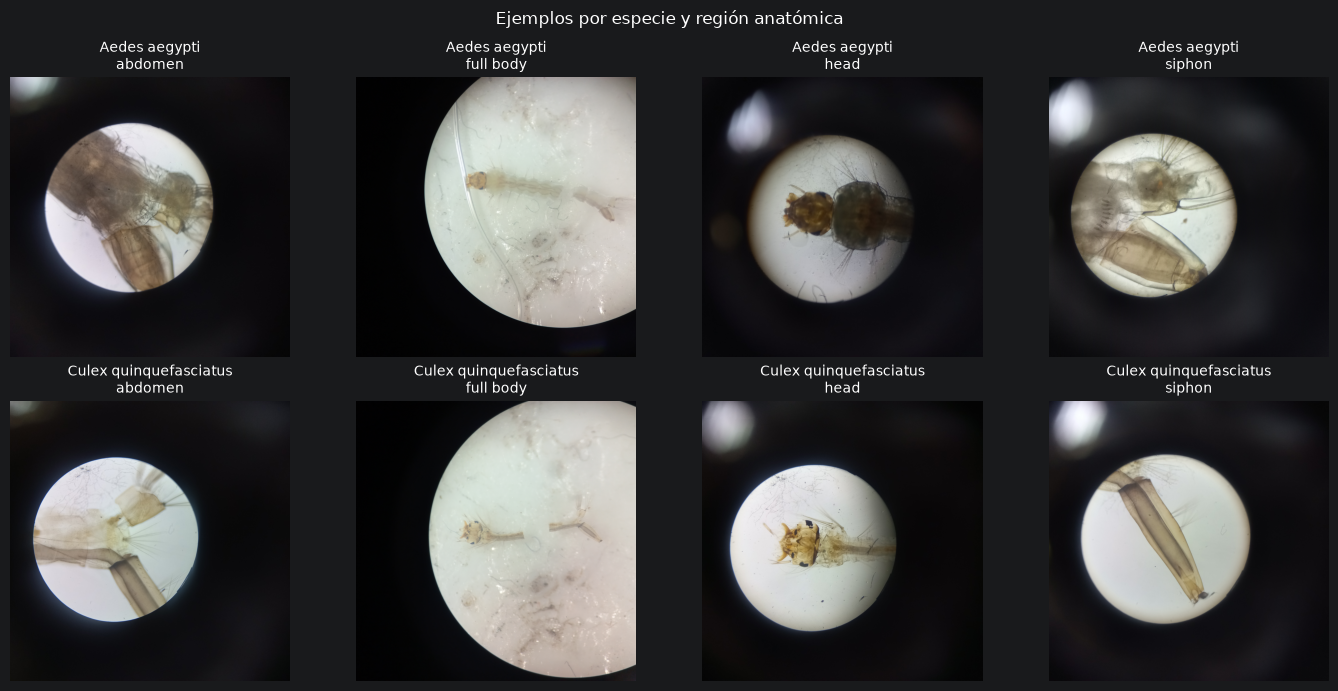

In [11]:
fig, ejes = plt.subplots(len(ESPECIES), len(REGIONES), figsize=(14, 7))
for i, especie in enumerate(ESPECIES):
    for j, region in enumerate(REGIONES):
        ax = ejes[i, j]
        grupo = df[(df["Especie"] == especie) & (df["Región"] == region)]
        if not grupo.empty:
            with Image.open(grupo.iloc[0]["Ruta"]) as im:
                ax.imshow(im.convert("RGB"))
        ax.set_title(f"{especie}\n{region}", fontsize=10)
        ax.axis("off")
plt.suptitle("Ejemplos por especie y región anatómica")
plt.tight_layout()
plt.show()

## 12. Dimensiones: ancho y alto

Se calculan estadísticas descriptivas de las dimensiones y se comparan entre especies.

In [12]:
display(df.groupby("Especie")[["Ancho", "Alto"]].describe().round(2))

Ancho                                                \
                        count     mean  std     min     25%     50%     75%   
Especie                                                                       
Aedes aegypti           400.0  3456.03  0.6  3456.0  3456.0  3456.0  3456.0   
Culex quinquefasciatus  400.0  3456.00  0.0  3456.0  3456.0  3456.0  3456.0   

                                 Alto                                        \
                           max  count     mean  std     min     25%     50%   
Especie                                                                       
Aedes aegypti           3468.0  400.0  3456.03  0.6  3456.0  3456.0  3456.0   
Culex quinquefasciatus  3456.0  400.0  3456.00  0.0  3456.0  3456.0  3456.0   

                                        
                           75%     max  
Especie                                 
Aedes aegypti           3456.0  3468.0  
Culex quinquefasciatus  3456.0  3456.0

## 13. Resoluciones diferentes

Se contabilizan los tamaños de imagen y se identifican las resoluciones más frecuentes.

In [13]:
tabla_resoluciones = df["Resolución"].value_counts().reset_index()
tabla_resoluciones.columns = ["Resolución", "Cantidad"]
print("Resoluciones diferentes:", df["Resolución"].nunique())
display(tabla_resoluciones.head(15))

Resoluciones diferentes: 2


,Resolución,Cantidad
0,3456x3456,799
1,3468x3468,1


## 14. Relación de aspecto

Se evalúa si las imágenes son cuadradas, horizontales o verticales. Esto ayuda a decidir cómo redimensionarlas sin distorsionar las estructuras de las larvas.

count  mean  std  min  25%  50%  75%  max
Especie                Región                                              
Aedes aegypti          abdomen    100.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
                       full body  100.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
                       head       100.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
                       siphon     100.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
Culex quinquefasciatus abdomen    100.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
                       full body  100.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
                       head       100.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0
                       siphon     100.0   1.0  0.0  1.0  1.0  1.0  1.0  1.0

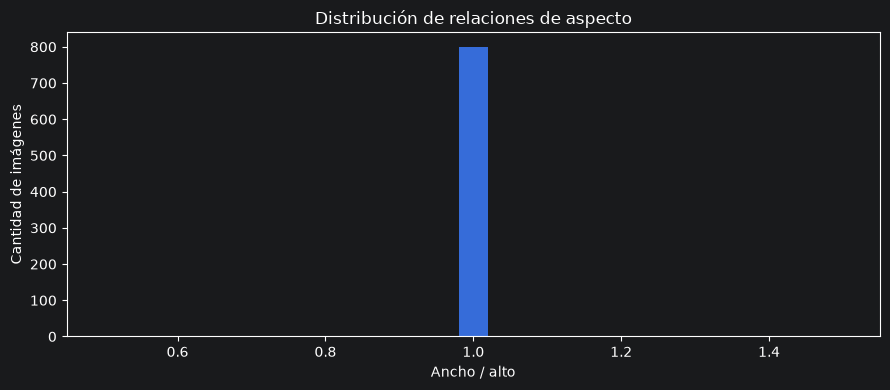

In [14]:
display(df.groupby(["Especie", "Región"])["Relación de aspecto"].describe().round(3))

plt.figure(figsize=(9, 4))
plt.hist(df["Relación de aspecto"], bins=25)
plt.xlabel("Ancho / alto")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de relaciones de aspecto")
plt.tight_layout()
plt.show()

## 15. Formatos reales y extensiones

Se compara la extensión del nombre del archivo con el formato que identifica Pillow.

In [15]:
display(pd.crosstab(df["Extensión"], df["Formato real"], margins=True))
formato_esperado = {".jpg": "JPEG", ".jpeg": "JPEG", ".png": "PNG", ".webp": "WEBP",
                    ".bmp": "BMP", ".tif": "TIFF", ".tiff": "TIFF"}
df["Formato inconsistente"] = df.apply(
    lambda fila: formato_esperado.get(fila["Extensión"]) != fila["Formato real"], axis=1
)
print("Archivos con extensión/formato inconsistentes:", int(df["Formato inconsistente"].sum()))

Formato real,JPEG,All
Extensión,,
.jpg,800,800
All,800,800


Archivos con extensión/formato inconsistentes: 0


## 16. Modos y canales de color

Se revisan los modos de representación: RGB, escala de grises, RGBA u otros.

In [16]:
display(pd.crosstab(df["Especie"], df["Modo de color"], margins=True))

Modo de color,RGB,All
Especie,,
Aedes aegypti,400,400
Culex quinquefasciatus,400,400
All,800,800


## 17. Tamaño de los archivos

Se describen los tamaños de almacenamiento (KB) de las imágenes por especie y región.

count     mean     std      min      25%  \
Especie                Región                                                
Aedes aegypti          abdomen    100.0  1894.42  164.32   795.18  1881.43   
                       full body  100.0  2134.91  241.56  1326.94  2075.11   
                       head       100.0  1765.26  275.27  1383.99  1490.48   
                       siphon     100.0  1958.95  129.58  1792.66  1879.22   
Culex quinquefasciatus abdomen    100.0  1885.72   61.13  1769.09  1840.74   
                       full body  100.0  2103.26  258.76  1656.49  1868.96   
                       head       100.0  1828.99  403.32  1379.39  1504.53   
                       siphon     100.0  1860.03   57.65  1753.62  1820.40   

                                      50%      75%      max  
Especie                Región                                
Aedes aegypti          abdomen    1916.98  1952.26  2072.16  
                       full body  2222.58  2291.91  2408.73  
                       head       1801.05  2033.97  2263.55  
                       siphon     1928.81  1988.08  2421.99  
Culex quinquefasciatus abdomen    1885.36  1918.04  2079.60  
                       full body  2217.62  2339.75  2557.79  
                       head       1577.26  2180.45  2490.06  
                       siphon     1858.04  1893.97  2089.09

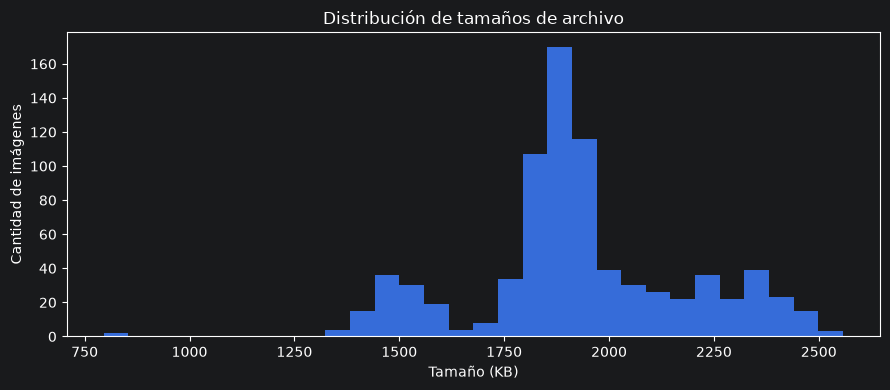

In [17]:
display(df.groupby(["Especie", "Región"])["Tamaño (KB)"].describe().round(2))

plt.figure(figsize=(9, 4))
plt.hist(df["Tamaño (KB)"], bins=30)
plt.xlabel("Tamaño (KB)")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de tamaños de archivo")
plt.tight_layout()
plt.show()

## 18. Análisis de brillo

Se analiza el promedio de intensidad de las fotografías, en escala de 0 a 255.

,count,mean,std,min,25%,50%,75%,max
Especie,,,,,,,,
Aedes aegypti,400.0,79.70,24.02,46.00,63.35,69.19,94.58,134.61
Culex quinquefasciatus,400.0,81.81,25.71,58.32,65.01,69.26,88.08,136.36


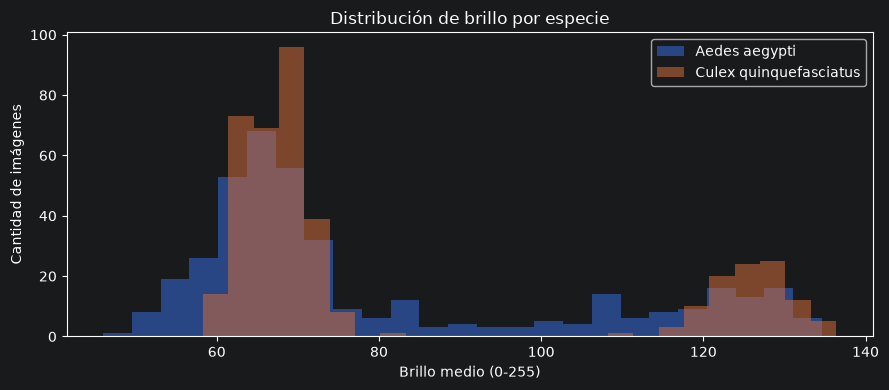

In [18]:
display(df.groupby("Especie")["Brillo"].describe().round(2))

plt.figure(figsize=(9, 4))
for especie in ESPECIES:
    plt.hist(df.loc[df["Especie"] == especie, "Brillo"], bins=25, alpha=0.55, label=especie)
plt.xlabel("Brillo medio (0-255)")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de brillo por especie")
plt.legend()
plt.tight_layout()
plt.show()

## 19. Análisis de contraste

Se utiliza la desviación estándar de la intensidad en escala de grises como aproximación al contraste de cada fotografía.

,count,mean,std,min,25%,50%,75%,max
Especie,,,,,,,,
Aedes aegypti,400.0,81.31,8.54,55.19,76.34,79.05,85.58,109.54
Culex quinquefasciatus,400.0,84.43,5.36,74.29,80.73,82.74,88.41,98.42


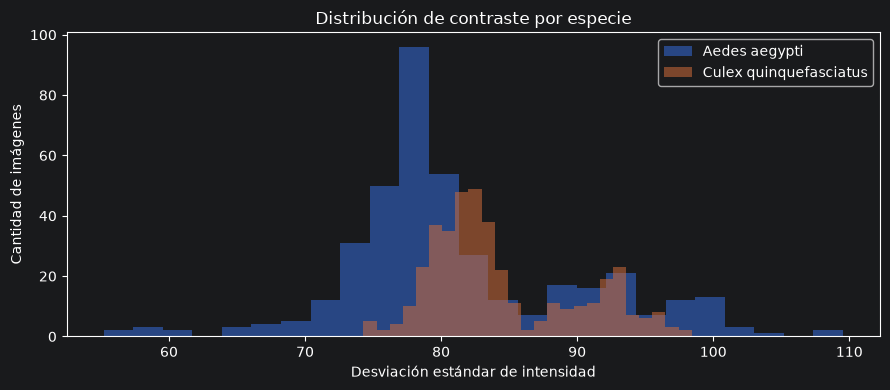

In [19]:
display(df.groupby("Especie")["Contraste"].describe().round(2))

plt.figure(figsize=(9, 4))
for especie in ESPECIES:
    plt.hist(df.loc[df["Especie"] == especie, "Contraste"], bins=25, alpha=0.55, label=especie)
plt.xlabel("Desviación estándar de intensidad")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de contraste por especie")
plt.legend()
plt.tight_layout()
plt.show()

## 20. Análisis de nitidez

Se calcula la varianza del Laplaciano sobre una copia reducida de cada imagen. Los valores menores pueden indicar desenfoque, aunque también dependen de la textura y del contenido de la fotografía.

,count,mean,std,min,25%,50%,75%,max
Especie,,,,,,,,
Aedes aegypti,400.0,183.51,69.71,59.56,131.70,174.43,220.09,545.97
Culex quinquefasciatus,400.0,202.14,74.84,67.62,142.56,192.33,250.11,515.02


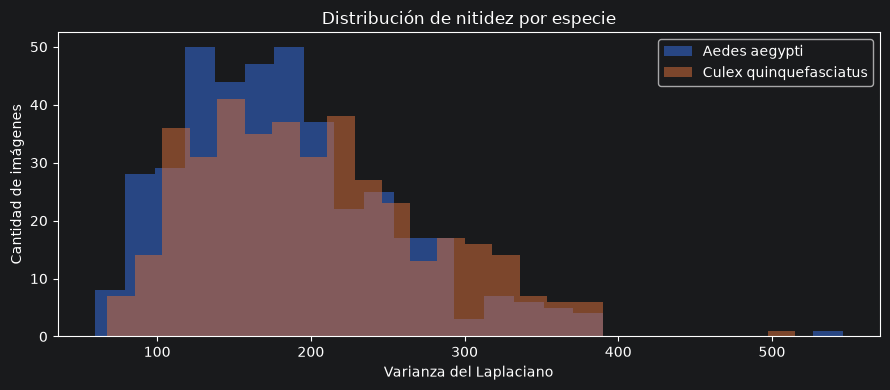

In [20]:
display(df.groupby("Especie")["Nitidez"].describe().round(2))

plt.figure(figsize=(9, 4))
for especie in ESPECIES:
    plt.hist(df.loc[df["Especie"] == especie, "Nitidez"], bins=25, alpha=0.55, label=especie)
plt.xlabel("Varianza del Laplaciano")
plt.ylabel("Cantidad de imágenes")
plt.title("Distribución de nitidez por especie")
plt.legend()
plt.tight_layout()
plt.show()

## 21. Comparación de calidad visual por región

Se comparan brillo, contraste y nitidez por parte anatómica. Las diferencias pueden relacionarse con el modo de captura y afectar el aprendizaje de la CNN.

Brillo  Contraste  Nitidez
Especie                Región                               
Aedes aegypti          abdomen     67.07      77.53   150.15
                       full body  120.96      92.86   216.50
                       head        60.67      78.19   180.42
                       siphon      69.06      78.97   157.09
Culex quinquefasciatus abdomen     67.98      80.52   158.89
                       full body  125.84      92.31   262.42
                       head        64.01      82.13   206.82
                       siphon      69.45      82.30   147.23

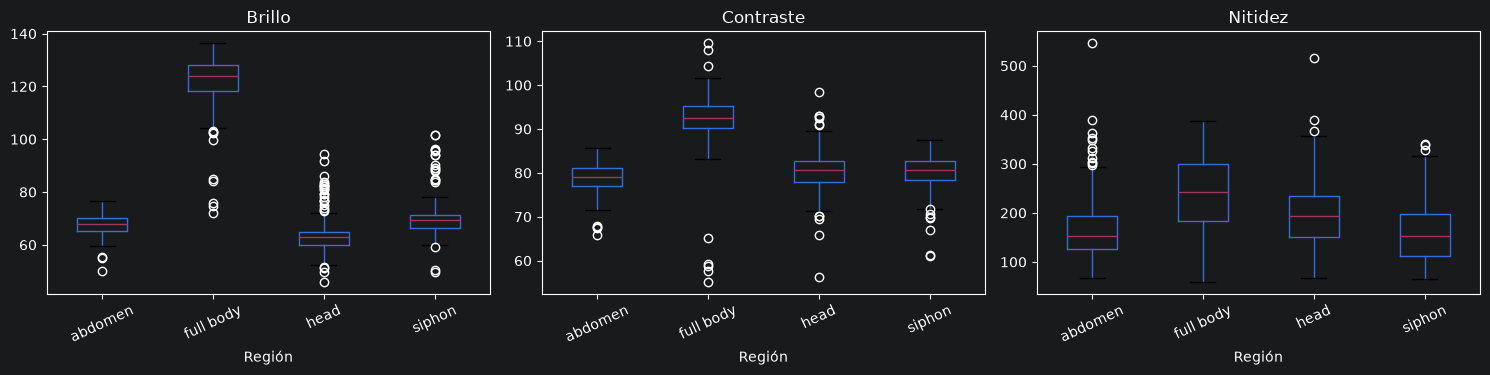

In [21]:
tabla_calidad = df.groupby(["Especie", "Región"])[["Brillo", "Contraste", "Nitidez"]].median().round(2)
display(tabla_calidad)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
for ax, variable in zip(ejes, ["Brillo", "Contraste", "Nitidez"]):
    df.boxplot(column=variable, by="Región", ax=ax, grid=False, rot=25)
    ax.set_title(variable)
    ax.set_xlabel("Región")
plt.suptitle("")
plt.tight_layout()
plt.show()

## 22. Revisión visual de valores extremos

Se presentan las fotografías con menor y mayor nitidez y brillo. Los valores extremos son candidatos a inspección manual, no errores confirmados.

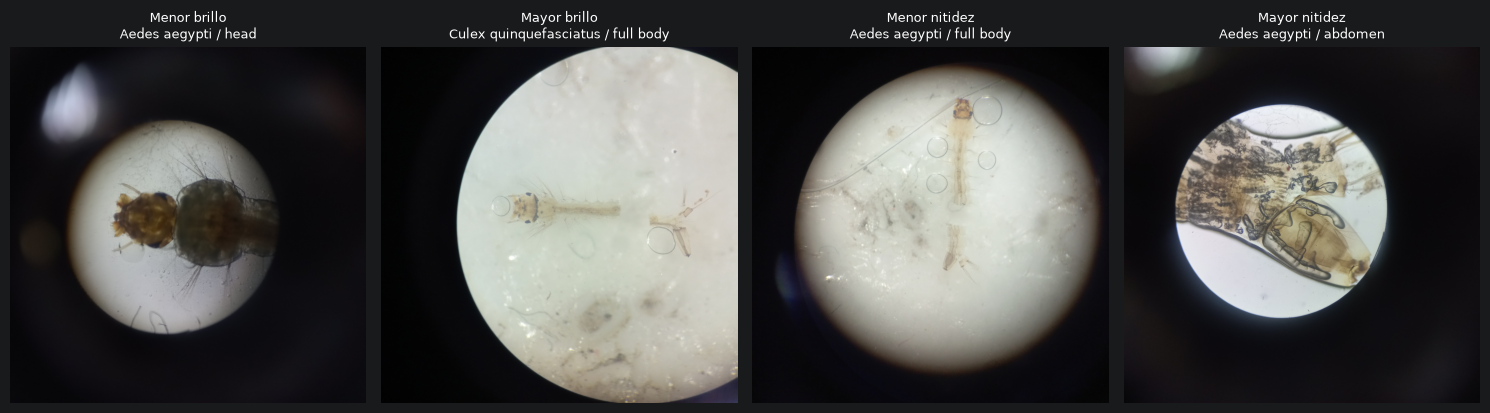

In [22]:
extremos = [
    ("Menor brillo", df.nsmallest(1, "Brillo")),
    ("Mayor brillo", df.nlargest(1, "Brillo")),
    ("Menor nitidez", df.nsmallest(1, "Nitidez")),
    ("Mayor nitidez", df.nlargest(1, "Nitidez")),
]
fig, ejes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (etiqueta, grupo) in zip(ejes, extremos):
    fila = grupo.iloc[0]
    with Image.open(fila["Ruta"]) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title(f"{etiqueta}\n{fila['Especie']} / {fila['Región']}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 23. Detección de duplicados exactos (SHA-256)

Se detectan archivos idénticos por su contenido binario. Se contabilizan las copias adicionales y los grupos de fotografías repetidas.

In [23]:
grupos_duplicados = df[df.duplicated("SHA256", keep=False)].sort_values("SHA256")
numero_duplicados = int(df.duplicated("SHA256").sum())
print("Duplicados exactos adicionales:", numero_duplicados)
print("Grupos de duplicados:", grupos_duplicados["SHA256"].nunique())
display(grupos_duplicados[["Especie", "Región", "Archivo", "SHA256"]].head(15))

Duplicados exactos adicionales: 0
Grupos de duplicados: 0


,Especie,Región,Archivo,SHA256


## 24. Posibles duplicados visuales (dHash)

Se identifican fotografías que comparten una misma huella visual aproximada, pero que no son idénticas a nivel de archivo. **Son candidatos para revisión manual:** imágenes microscópicas parecidas pueden compartir esta huella sin ser realmente la misma fotografía.

In [24]:
candidatos = df[df.duplicated("dHash", keep=False) & ~df.duplicated("SHA256", keep=False)]
print("Imágenes candidatas con huella dHash compartida y sin duplicado binario:", len(candidatos))
print("Grupos de dHash candidatos:", candidatos["dHash"].nunique())
display(candidatos[["Especie", "Región", "Archivo", "dHash"]].head(15))

Imágenes candidatas con huella dHash compartida y sin duplicado binario: 0
Grupos de dHash candidatos: 0


,Especie,Región,Archivo,dHash


## 25. Duplicados entre especies o regiones

Se comprueba si un mismo archivo aparece etiquetado en especies o partes anatómicas diferentes. Esto podría indicar errores de clasificación o riesgo de fuga de información.

In [25]:
duplicados_cruzados = (
    df.groupby("SHA256").agg(
        Especies=("Especie", "nunique"), Regiones=("Región", "nunique"), Archivos=("Archivo", "size")
    )
)
conflictos_especie = duplicados_cruzados[duplicados_cruzados["Especies"] > 1]
conflictos_region = duplicados_cruzados[duplicados_cruzados["Regiones"] > 1]
print("Grupos con archivo idéntico en especies diferentes:", len(conflictos_especie))
print("Grupos con archivo idéntico en regiones diferentes:", len(conflictos_region))
display(duplicados_cruzados[(duplicados_cruzados["Especies"] > 1) | (duplicados_cruzados["Regiones"] > 1)].head(10))

Grupos con archivo idéntico en especies diferentes: 0
Grupos con archivo idéntico en regiones diferentes: 0


,Especies,Regiones,Archivos
SHA256,,,


## 26. Integridad y estructura esperada

Se revisan los archivos dañados y la presencia de las ocho combinaciones esperadas de especie y región.

In [26]:
estructura = []
for especie in ESPECIES:
    for region in REGIONES:
        carpeta = ruta / especie / region
        estructura.append({"Especie": especie, "Región": region,
                           "Existe carpeta": carpeta.is_dir(),
                           "Imágenes válidas": int(((df["Especie"] == especie) & (df["Región"] == region)).sum())})
display(pd.DataFrame(estructura))
print("Archivos dañados:", len(df_errores))
if not df_errores.empty:
    display(df_errores.head(10))

,Especie,Región,Existe carpeta,Imágenes válidas
0,Aedes aegypti,abdomen,True,100
1,Aedes aegypti,full body,True,100
2,Aedes aegypti,head,True,100
3,Aedes aegypti,siphon,True,100
4,Culex quinquefasciatus,abdomen,True,100
5,Culex quinquefasciatus,full body,True,100
6,Culex quinquefasciatus,head,True,100
7,Culex quinquefasciatus,siphon,True,100


Archivos dañados: 0


## 27. Análisis del desbalance de clases y regiones

Se calcula la relación entre el grupo más frecuente y el menos frecuente, tanto a nivel de especie como en las combinaciones de especie y región.

In [27]:
mayor_especie = int(conteo_especies.max())
menor_especie = int(conteo_especies.min())
conteos_combinaciones = tabla_especie_region.to_numpy().ravel()
positivos = conteos_combinaciones[conteos_combinaciones > 0]
relacion_especies = mayor_especie / menor_especie if menor_especie else np.nan
relacion_subgrupos = positivos.max() / positivos.min() if len(positivos) and len(positivos) == len(conteos_combinaciones) else np.nan

print(f"Relación entre especies: {relacion_especies:.2f}:1" if not np.isnan(relacion_especies) else "Falta una especie")
print(f"Relación entre las 8 combinaciones: {relacion_subgrupos:.2f}:1" if not np.isnan(relacion_subgrupos) else "Falta alguna combinación")
display(tabla_especie_region)

Relación entre especies: 1.00:1
Relación entre las 8 combinaciones: 1.00:1


Región,abdomen,full body,head,siphon
Especie,,,,
Aedes aegypti,100,100,100,100
Culex quinquefasciatus,100,100,100,100


## 28. Resumen  del EDA

Se consolidan los principales resultados para utilizarlos posteriormente en la conclusión final. Este resumen se actualiza cuando se vuelve a ejecutar el notebook sobre los archivos reales.

In [28]:
resumen_eda = pd.DataFrame([
    ("Imágenes de archivo revisadas", len(df) + len(df_errores)),
    ("Imágenes válidas", len(df)),
    ("Archivos dañados", len(df_errores)),
    ("Especies presentes", df["Especie"].nunique()),
    ("Regiones presentes", df["Región"].nunique()),
    ("Combinaciones especie-región presentes", int((tabla_especie_region > 0).sum().sum())),
    ("Resoluciones diferentes", df["Resolución"].nunique()),
    ("Modos de color diferentes", df["Modo de color"].nunique()),
    ("Formatos reales diferentes", df["Formato real"].nunique()),
    ("Archivos con formato inconsistente", int(df["Formato inconsistente"].sum())),
    ("Duplicados exactos adicionales", numero_duplicados),
    ("Grupos duplicados entre especies", len(conflictos_especie)),
    ("Grupos duplicados entre regiones", len(conflictos_region)),
    ("Candidatos visuales con dHash compartido", len(candidatos)),
    ("Brillo medio", round(df["Brillo"].mean(), 2)),
    ("Contraste medio", round(df["Contraste"].mean(), 2)),
    ("Nitidez mediana", round(df["Nitidez"].median(), 2)),
    ("Relación de desbalance entre especies", round(relacion_especies, 2) if not np.isnan(relacion_especies) else np.nan),
    ("Relación de desbalance entre subgrupos", round(relacion_subgrupos, 2) if not np.isnan(relacion_subgrupos) else np.nan),
], columns=["Indicador", "Valor"])

display(resumen_eda)
print("\nDistribución por especie:")
display(tabla_especies)
print("\nDistribución por especie y región anatómica:")
display(tabla_especie_region)
print("\nResumen de brillo, contraste y nitidez por especie y región:")
display(tabla_calidad)

,Indicador,Valor
0,Imágenes de archivo revisadas,800.00
1,Imágenes válidas,800.00
2,Archivos dañados,0.00
3,Especies presentes,2.00
4,Regiones presentes,4.00
5,Combinaciones especie-región presentes,8.00
6,Resoluciones diferentes,2.00
7,Modos de color diferentes,1.00
8,Formatos reales diferentes,1.00
9,Archivos con formato inconsistente,0.00



Distribución por especie:


,Cantidad,Porcentaje (%)
Especie,,
Aedes aegypti,400,50.0
Culex quinquefasciatus,400,50.0



Distribución por especie y región anatómica:


Región,abdomen,full body,head,siphon
Especie,,,,
Aedes aegypti,100,100,100,100
Culex quinquefasciatus,100,100,100,100



Resumen de brillo, contraste y nitidez por especie y región:


Brillo  Contraste  Nitidez
Especie                Región                               
Aedes aegypti          abdomen     67.07      77.53   150.15
                       full body  120.96      92.86   216.50
                       head        60.67      78.19   180.42
                       siphon      69.06      78.97   157.09
Culex quinquefasciatus abdomen     67.98      80.52   158.89
                       full body  125.84      92.31   262.42
                       head        64.01      82.13   206.82
                       siphon      69.45      82.30   147.23


## 29. Conclusiones generales del EDA

El análisis exploratorio del dataset MLMI-2024 permitió evaluar las características, distribución, calidad e integridad de las imágenes microscópicas de larvas de mosquitos Aedes aegypti y Culex quinquefasciatus.

El objetivo fue identificar las condiciones del conjunto de datos y los aspectos que deben considerarse antes de utilizarlo para desarrollar el modelo adicional de identificación de larvas del proyecto VectorIA.

### 29.1. Principales hallazgos

1. **Cantidad de imágenes:** se analizaron 800 imágenes microscópicas correspondientes a dos especies: Aedes aegypti y Culex quinquefasciatus.

2. **Distribución de especies:** ambas clases contienen 400 imágenes (50 % cada una), con una relación de desbalance de 1,00:1. Esta distribución equilibrada es favorable para el entrenamiento de un clasificador.

3. **Regiones anatómicas:** el dataset contiene cuatro regiones: abdomen, cuerpo completo (full body), cabeza (head) y sifón (siphon). Cada especie cuenta con 100 imágenes por región, formando ocho subgrupos equilibrados.

4. **Dimensiones:** se identificaron dos resoluciones diferentes. Sin embargo, las imágenes mantienen una relación de aspecto de 1:1, por lo que presentan una forma cuadrada. Será necesario estandarizar sus dimensiones según la arquitectura del modelo.

5. **Formatos y canales de color:** se encontró un único formato real y un único modo de color, sin inconsistencias detectadas. Esto facilita el procesamiento de las fotografías.

6. **Brillo:** el brillo promedio general fue de 80,76 en una escala de 0 a 255. Se observaron diferencias importantes entre las regiones anatómicas. Las imágenes de cuerpo completo presentan mayor brillo, con promedios de 120,96 para Aedes aegypti y 125,84 para Culex quinquefasciatus, mientras que las demás regiones presentan valores principalmente entre 60 y 70.

7. **Contraste:** el contraste promedio general fue de 82,87. Las imágenes de cuerpo completo presentan los valores más altos, cercanos a 92 en ambas especies. Las regiones restantes presentan valores principalmente entre 77 y 82. Esto indica que el contraste varía según el tipo de fotografía anatómica.

8. **Nitidez:** la mediana general fue de 179,46, calculada mediante la varianza del Laplaciano. Se observaron diferencias entre regiones y especies. Las imágenes de cuerpo completo de Culex quinquefasciatus presentan un valor mediano de 262,42, mientras que las imágenes de sifón muestran valores de 157,09 y 147,23 para Aedes y Culex, respectivamente.

9. **Tamaño de archivos:** las imágenes presentan tamaños de almacenamiento variables, concentrados principalmente entre 1.750 y 2.100 KB, aunque existen fotografías más pequeñas y otras de aproximadamente 2.500 KB.

10. **Integridad:** las 800 imágenes pudieron abrirse y procesarse correctamente. No se encontraron archivos dañados ni inconsistencias entre sus extensiones y formatos reales.

11. **Duplicados exactos:** no se identificaron archivos duplicados mediante SHA-256. Tampoco se encontraron grupos duplicados entre especies o regiones anatómicas.

12. **Similitud visual:** no se identificaron candidatos con dHash compartido mediante el procedimiento utilizado. Esto no descarta completamente la existencia de fotografías similares, pero no se encontraron coincidencias con este método.

13. **Desbalance de subgrupos:** la relación de desbalance entre las combinaciones de especie y región fue de 1,00:1. Esto confirma que las ocho categorías tienen la misma cantidad de imágenes.

### 29.2. Recomendaciones para el entrenamiento

- **Mantener el equilibrio:** conservar la distribución balanceada entre especies y regiones anatómicas durante la preparación de los datos.

- **Estandarizar dimensiones:** redimensionar las imágenes al tamaño requerido por la arquitectura CNN, procurando conservar los detalles microscópicos importantes.

- **Considerar las regiones anatómicas:** evaluar cómo influyen las fotografías de abdomen, cabeza, cuerpo completo y sifón en la identificación de las especies.

- **Evaluar diferencias de iluminación:** revisar los cambios de brillo y contraste entre regiones, evitando que el modelo aprenda características de iluminación en lugar de características morfológicas.

- **Revisar la nitidez:** inspeccionar las imágenes con valores extremos de varianza del Laplaciano para identificar posibles problemas de enfoque.

- **Mantener las etiquetas:** conservar la identificación tanto de la especie como de la región anatómica al organizar los datos.

- **Prevenir fugas de información:** si diferentes imágenes corresponden a una misma larva o sesión de captura, mantenerlas en el mismo conjunto durante la separación de entrenamiento, validación y prueba.

- **Aplicar aumento de datos cuando sea necesario:** utilizar transformaciones apropiadas que no alteren las características morfológicas relevantes para identificar las especies.

- **Evaluar por especie y región:** utilizar métricas como Precision, Recall y F1-score para comprobar el rendimiento individual de ambas especies y analizar posibles diferencias entre regiones.

- **Mantener separado el modelo de larvas:** este dataset contiene imágenes microscópicas, por lo que debe utilizarse para el bonus de identificación de larvas y no mezclarse directamente con las fotografías de mosquitos adultos de la CNN principal.

### 29.3. Conclusión final

El dataset MLMI-2024 presenta condiciones favorables para el desarrollo de un modelo de identificación de larvas de mosquitos, principalmente por su distribución equilibrada, organización por regiones anatómicas y ausencia de archivos dañados o duplicados detectados.

Una de sus principales fortalezas es que contiene la misma cantidad de imágenes para Aedes aegypti y Culex quinquefasciatus, tanto a nivel de especie como de región anatómica. Esto facilita una comparación más equilibrada durante el entrenamiento.

El análisis también permitió identificar diferencias de iluminación, contraste y nitidez entre las regiones estudiadas. Las imágenes de cuerpo completo presentan niveles de brillo y contraste superiores a los de otras regiones, mientras que la nitidez muestra variaciones que podrían influir en el reconocimiento de detalles microscópicos.

Aunque el conjunto presenta una estructura adecuada, será necesario realizar un preprocesamiento que estandarice sus dimensiones y considere las diferencias visuales observadas.

Además, se recomienda verificar que las particiones de entrenamiento y prueba sean independientes y mantener las etiquetas correspondientes a cada región anatómica.

En conclusión, MLMI-2024 constituye una fuente útil para implementar la funcionalidad adicional de identificación de larvas en VectorIA. Su equilibrio entre clases y su organización anatómica representan ventajas importantes, aunque el rendimiento final deberá comprobarse mediante el entrenamiento y la evaluación del modelo.
